# 0 · Configuración de datasets Ecobici

**Datos:** 4 CSV aportados por el usuario en `data/raw/`. Se puede hacer la extracción de la data de viajes usando el .py ubicado en `src/descarga.py`. La georeferenciación de la data se descargo directo del URL ubicado en el readme. Se calculan resultados sobre estos archivos, sin simular registros ni cambiar las fuentes.

In [1]:
from pathlib import Path
import pandas as pd
import sys
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.limpieza import missing_profile, frecuencias, detectar_outliers_zscore
from src.graficas import histograma



RAW_DIR = RAIZ / "data" / "raw"

archivos_viajes = sorted(RAW_DIR.glob("ecobici_2026-0[1-3].csv"))
print("Archivos de viajes encontrados:", [a.name for a in archivos_viajes])
assert len(archivos_viajes) == 3, f"Se esperaban 3 archivos y hay {len(archivos_viajes)} en {RAW_DIR}"

df_ecobici = pd.DataFrame()

for file in archivos_viajes:
    df = pd.read_csv(file)
    df_ecobici = pd.concat([df_ecobici,df], ignore_index=True)

# --- Estaciones ---
df_estaciones = pd.read_csv(RAW_DIR / "cicloestacion.csv")

print("viajes    :", df_ecobici.shape)
print("estaciones:", df_estaciones.shape)
df_ecobici.head()

Archivos de viajes encontrados: ['ecobici_2026-01.csv', 'ecobici_2026-02.csv', 'ecobici_2026-03.csv']
viajes    : (4707285, 9)
estaciones: (677, 10)


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo
0,M,30.0,4933404,059,31/12/2025,23:25:20,565,01/01/2026,00:00:16
1,M,27.0,4162376,180,31/12/2025,23:43:53,672,01/01/2026,00:00:31
2,M,29.0,3749272,014,31/12/2025,23:52:15,030,01/01/2026,00:00:50
3,M,44.0,5680772,014,31/12/2025,23:46:43,145,01/01/2026,00:00:53
4,M,22.0,5128459,031,31/12/2025,23:39:58,155,01/01/2026,00:01:05


# 1 · Comprensión de los datos


# 2 · Primera exploración de los datos



# 3 · Calidad, limpieza y transformación

Dentro de este bloque realizaremos limpieza, imputación, eliminación de atipicos para poder contar con la calidad necesaria para los análisis que siguen


## 3.1 Detección y tratamiento de NA

In [ ]:
falt_ecobici = missing_profile(df_ecobici)
falt_estaciones = missing_profile(df_estaciones)

display(falt_ecobici)
display(falt_estaciones) 

,variable,faltantes,porcentaje,tipo
0,Edad_Usuario,226,0.005,float64
1,Genero_Usuario,2,0.000,object
2,Bici,0,0.000,int64
3,Ciclo_Estacion_Retiro,0,0.000,object
4,Fecha_Retiro,0,0.000,object
5,Hora_Retiro,0,0.000,object
6,Ciclo_EstacionArribo,0,0.000,object
7,Fecha_Arribo,0,0.000,object
8,Hora_Arribo,0,0.000,object


,variable,faltantes,porcentaje,tipo
0,sistema,0,0.0,object
1,num_cicloe,0,0.0,object
2,calle_prin,0,0.0,object
3,calle_secu,0,0.0,object
4,colonia,0,0.0,object
5,alcaldia,0,0.0,object
6,latitud,0,0.0,float64
7,longitud,0,0.0,float64
8,sitio_de_e,0,0.0,object
9,estatus,0,0.0,object


### 3.1.1 Eliminar NA

Al tener un porcentaje tan bajo de NA, se podría optar por eliminar los datos faltantes. Sin embargo, también se añadiran métodos de imputación para fines del proyecto.

### 3.1.2 Imputación

Se imputaran los datos faltantes de las variables `'Edad_Usuario'`  para fines demostrativos. Los faltantes de `'Genero_Usuario'` se eliminarán

In [ ]:
mediana_edad = df_ecobici["Edad_Usuario"].median()

# Marca primero cuáles eran faltantes, para poder identificarlos después

df_ecobici["Edad_Usuario"] = df_ecobici["Edad_Usuario"].fillna(mediana_edad)

print("Mediana usada:", mediana_edad)
print("Faltantes restantes:", df_ecobici["Edad_Usuario"].isna().sum())

Mediana usada: 33.0
Faltantes restantes: 0


## 3.2 Detección de outliers
Se realizará el análisis sobre la variable de `'Edad_Usuario'` y sobre la variable creada `'Duracion'` 

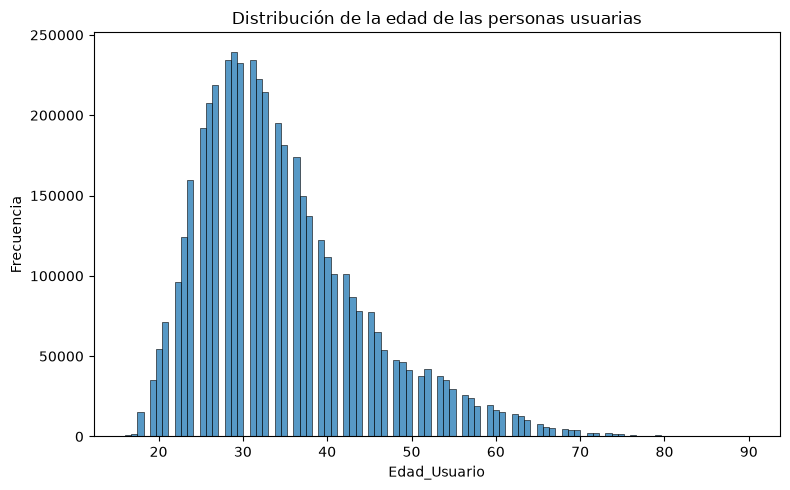

In [12]:
histograma(df_ecobici, "Edad_Usuario", bins=100,
           titulo="Distribución de la edad de las personas usuarias")

## 3.2.1 IQR

Detección de outliers por IQR

In [6]:
s = df_ecobici["Edad_Usuario"]
print(s.describe().round(2))

q1, q3 = s.quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
lim_inf = q3 - 1.5 * (q3 - q1)

print("Límite superior (IQR):", lim_sup, "| registros por encima:", (s > lim_sup).sum())
print("Límite inferior (IQR):", lim_inf, "| registros por debajo:", (s < lim_inf).sum())

print(s[s >= 75].value_counts().sort_index())

count    4707059.00
mean          34.59
std            9.85
min           16.00
25%           28.00
50%           33.00
75%           40.00
max          100.00
Name: Edad_Usuario, dtype: float64
Límite superior (IQR): 58.0 | registros por encima: 132453
Límite inferior (IQR): 22.0 | registros por debajo: 177780
Edad_Usuario
75.0     1503
76.0      945
77.0      393
78.0      307
79.0      679
80.0      245
81.0      269
82.0       74
83.0      187
84.0       77
85.0       28
86.0       32
87.0        3
90.0       10
96.0       43
100.0      10
Name: count, dtype: int64


Con el mínimo detectamos que no hay menores a 16 (Justo es lo que dice la política), por lo que los outliers van a estar en el lado derecho de la cola. Sin embargo al usar el método de IQR para detectar, podemos ver que realmente la distribución va disminuyendo. Los únicos datos que podrían ser clasificados como atípicos, son de 90+ porque se pierde la consistencua que se tenía en las otras edades. Se eliminan los valores mayores a 90

## 3.2.2 Z-Score

Se hará la revisión también con Z-Scpore para validar si ambos métodos coinciden con las conclusiones

In [7]:
z, es_outlier = detectar_outliers_zscore(df_ecobici, "Edad_Usuario", umbral=3)

media, desv = df_ecobici["Edad_Usuario"].agg(["mean", "std"])
print(f"Umbral |z| > 3  ->  edad < {media - 3*desv:.2f}  o  edad > {media + 3*desv:.2f}")
print(f"Outliers: {es_outlier.sum():,} de {df_ecobici['Edad_Usuario'].notna().sum():,} "
      f"({es_outlier.mean():.2%})")

Umbral |z| > 3  ->  edad < 5.03  o  edad > 64.15
Outliers: 44,295 de 4,707,059 (0.94%)


Al hacer la revisión, detectamos que 3 devstd está en 64.15 que perfectamente puede seguir siendo parte de la muestra. No hay elementos suficientes para eliminar lo que no entre en este rango. Mantenemos la decisión de eliminar mayores a 90

In [9]:
n_antes = len(df_ecobici)

df_ecobici = df_ecobici[~(df_ecobici["Edad_Usuario"] > 90)].reset_index(drop=True)

print(f"Registros eliminados: {n_antes - len(df_ecobici):,} "
      f"({(n_antes - len(df_ecobici)) / n_antes:.4%})")
print("Edad máxima ahora:", df_ecobici["Edad_Usuario"].max())

Registros eliminados: 53 (0.0011%)
Edad máxima ahora: 90.0


## 3.2 Categorización de variables

# 4 · Análisis por pregunta de investigación



# 5 · Conclusiones y limitaciones

